# Corn NIR benchmark (Cargill / Eigenvector)

This notebook walks through SpectoPrep on the public **corn** NIR dataset
(`m5` instrument): raw spectra, nested cross-validated optimisation, consensus
preprocessing per constituent, and predicted-versus-reference plots.

Constituents: **Moisture**, **Oil**, **Protein**, **Starch**.

> Full paper-grade nested CV (`init_points=10`, `n_iter=50`, i.e. 60 evaluations
> × 5 outer folds × 4 constituents) takes several minutes per seed. The paper
> reports the mean ± SD over ten seeds (0–9); `examples/run_corn_benchmark.py`
> runs one seed (seed 0) and `examples/corn_results/multiseed_summary.json`
> holds the ten-seed summary. Prefer loading these precomputed results, or use
> the shorter live demo cells below.


## 1. Load data

In [1]:
from pathlib import Path
import json
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

from spectoprep import PipelineOptimizer, SpectroPrepPlotter

COMPONENTS = ["Moisture", "Oil", "Protein", "Starch"]

# Resolve repo examples/ whether this notebook is under docs/notebooks/ or notebook/
for candidate in [Path("../../examples"), Path("../examples"), Path("examples")]:
    if candidate.exists():
        EXAMPLES = candidate.resolve()
        break
else:
    EXAMPLES = Path("examples").resolve()

CORN_CANDIDATES = [
    EXAMPLES / "data" / "corn.mat",
    Path("/tmp/spectoprep-data/corn.mat"),
]
CORN = next((p for p in CORN_CANDIDATES if p.exists()), None)
assert CORN is not None, (
    "Corn dataset not found. Place corn.mat at examples/data/corn.mat "
    "or /tmp/spectoprep-data/corn.mat (https://eigenvector.com/data/Corn/)."
)

d = sio.loadmat(CORN, struct_as_record=False, squeeze_me=True)
X = np.asarray(d["m5spec"].data, dtype=float)
Y = np.asarray(d["propvals"].data, dtype=float)
try:
    wavelengths = np.asarray(d["m5spec"].axisscale[1], dtype=float).ravel()
    if wavelengths.size != X.shape[1]:
        raise ValueError
except Exception:
    wavelengths = np.linspace(1100, 2498, X.shape[1])

print(f"Loaded {CORN}")
print(f"X={X.shape}, Y={Y.shape}, λ=[{wavelengths.min():.0f}, {wavelengths.max():.0f}] nm")
print("Constituents:", COMPONENTS)


Loaded /Users/habeebbabatunde/Downloads/Spectoprep-main/examples/data/corn.mat
X=(80, 700), Y=(80, 4), λ=[1100, 2498] nm
Constituents: ['Moisture', 'Oil', 'Protein', 'Starch']


## 2. Raw spectra (full set, inverted wavelength axis)

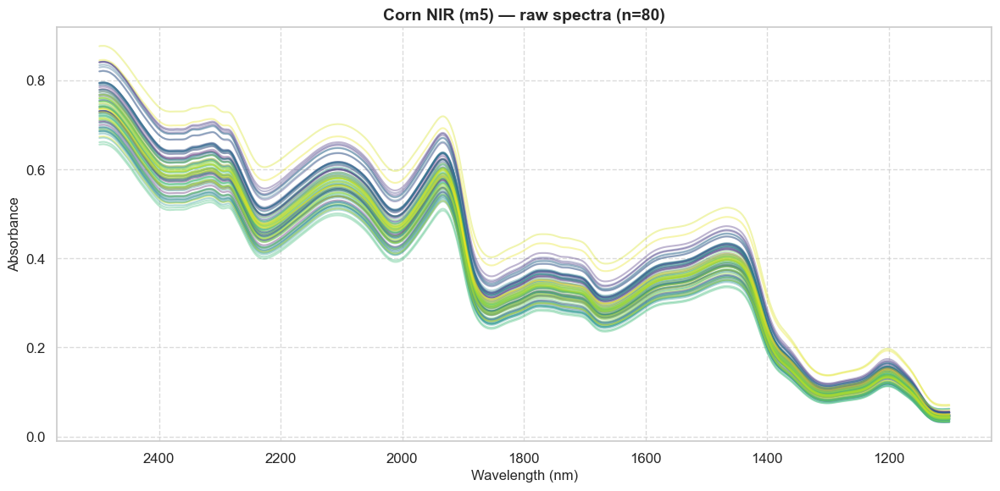

In [2]:
SpectroPrepPlotter.set_style(context="notebook", font_scale=1.1)
SpectroPrepPlotter.plot_spectra(
    wavelengths,
    X,
    title="Corn NIR (m5) — raw spectra (n=80)",
    xlabel="Wavelength (nm)",
    ylabel="Absorbance",
    alpha=0.35,
    invert_xaxis=True,
)
plt.show()


## 3. Load tracked optimal preprocessing (from full benchmark)

Run once from the repo root:

```bash
python examples/run_corn_benchmark.py
```

This writes `examples/corn_results/optimal_pipelines.json` with per-fold chains,
consensus pipelines, and nested-CV metrics for every constituent. These are the seed-0 results; the
ten-seed mean ± SD behind the paper's tables is shown right after.


In [3]:
results_path = EXAMPLES / "corn_results" / "optimal_pipelines.json"
if results_path.exists():
    summary = json.loads(results_path.read_text())
    print("Protocol:", json.dumps(summary["protocol"], indent=2))
    print("\nConsensus optimal preprocessing per constituent:")
    for name, block in summary["constituents"].items():
        chain = " → ".join(block["consensus_pipeline"])
        spx = block["spectoprep"]
        print(f"  {name:9s}: {chain}")
        print(f"             R²={spx['r2']:.3f}, RMSE={spx['rmse']:.4f}, RPD={spx['rpd']:.1f}")
        print(f"             fold chains: {block['fold_pipelines']}")
else:
    summary = None
    print(f"No precomputed results at {results_path}")
    print("Run: python examples/run_corn_benchmark.py")


Protocol: {
  "instrument": "m5",
  "outer_cv": "KFold(n_splits=5, shuffle=True, random_state=0)",
  "inner_cv": "group_kfold n_splits=3",
  "init_points": 10,
  "n_iter": 50,
  "evaluations_per_outer_fold": 60,
  "preprocessing_steps": [
    "snv",
    "msc",
    "savgol",
    "detrend",
    "scaler",
    "robust_scaler",
    "meancn"
  ]
}

Consensus optimal preprocessing per constituent:
  Moisture : scaler → meancn
             R²=1.000, RMSE=0.0077, RPD=49.6
             fold chains: [['scaler', 'meancn'], ['scaler', 'meancn'], ['scaler'], ['scaler', 'meancn'], ['scaler', 'meancn']]
  Oil      : detrend → scaler
             R²=0.973, RMSE=0.0291, RPD=6.1
             fold chains: [['detrend', 'scaler'], ['scaler', 'meancn'], ['detrend', 'robust_scaler'], ['detrend', 'scaler'], ['detrend', 'scaler']]
  Protein  : detrend → robust_scaler
             R²=0.990, RMSE=0.0488, RPD=10.2
             fold chains: [['detrend', 'robust_scaler'], ['detrend', 'scaler'], ['detrend', 'robust_s

### Ten-seed summary (paper tables)

Mean ± SD over seeds of the pooled out-of-fold metrics, from `examples/corn_results/multiseed_summary.json`.

In [4]:
multi_path = EXAMPLES / "corn_results" / "multiseed_summary.json"
if multi_path.exists():
    multi = json.loads(multi_path.read_text())
    proto = multi["protocol"]
    print(f"Seeds {proto['seeds'][0]}-{proto['seeds'][-1]} | init_points={proto['init_points']}, "
          f"n_iter={proto['n_iter']} | ridge alpha grid {proto['ridge_alpha_grid']}")
    print(f"{'Constituent':12s} {'Raw RMSE':>15s} {'SpectoPrep RMSE':>19s} {'SpectoPrep R²':>16s} {'RPD':>11s}")
    for name, block in multi["constituents"].items():
        raw, spx = block["raw"], block["spectoprep"]
        print(
            f"{name:12s} {raw['rmse']['mean']:7.3f} ± {raw['rmse']['sd']:.3f}"
            f"   {spx['rmse']['mean']:8.4f} ± {spx['rmse']['sd']:.4f}"
            f"   {spx['r2']['mean']:.3f} ± {spx['r2']['sd']:.3f}"
            f"   {spx['rpd']['mean']:5.1f} ± {spx['rpd']['sd']:.1f}"
        )
else:
    print(f"No ten-seed summary at {multi_path}")

Seeds 0-9 | init_points=10, n_iter=50 | ridge alpha grid logspace(-3, 3, 25)
Constituent         Raw RMSE     SpectoPrep RMSE    SpectoPrep R²         RPD
Moisture       0.046 ± 0.001     0.0080 ± 0.0008   1.000 ± 0.000    47.8 ± 4.9
Oil            0.078 ± 0.002     0.0303 ± 0.0050   0.970 ± 0.010     6.0 ± 1.0
Protein        0.180 ± 0.009     0.0627 ± 0.0133   0.983 ± 0.007     8.3 ± 2.1
Starch         0.408 ± 0.021     0.1080 ± 0.0175   0.982 ± 0.005     7.8 ± 1.4


## 4. Short live demo on one constituent (Protein)

A reduced search for interactive use. For paper numbers use the precomputed nested-CV results.


In [5]:
component = "Protein"
y = Y[:, COMPONENTS.index(component)]
groups = np.arange(len(y))

# Hold out 25% for a quick illustration (not the nested-CV paper protocol)
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=21).split(X, y, groups))

opt = PipelineOptimizer(
    X_train=X[tr], y_train=y[tr],
    X_test=X[te], y_test=y[te],
    groups=groups[tr],
    preprocessing_steps=["snv", "msc", "savgol", "detrend", "scaler", "robust_scaler", "meancn"],
    cv_method="group_kfold",
    n_splits=3,
    max_pipeline_length=2,
    allowed_preprocess_combinations=[1, 2],
    random_state=42,
    log_level="WARNING",
)
best_params, best_pipeline = opt.bayesian_optimize(init_points=5, n_iter=15)
preds, rmse, r2 = opt.get_best_pipeline_predictions(best_pipeline)
print("Selected:", " → ".join(s for s, _ in best_pipeline.steps[:-1]))
print(f"Held-out {component}: RMSE={rmse:.4f}, R²={r2:.4f}")


|   iter    |  target   |  als_lam  |   als_p   | als_niter | savgol... | savgol... | savgol... | detren... | detren... | emsc_o... | global... | lsnv_win  |  rnv_lp   |  rnv_up   | pca_n_... | rs_qua... | rs_qua... | rs_wit... | rs_wit... | minmax... | minmax... | power_... | power_... | quanti... | quanti... | ica_n_... | kpca_n... | kpca_k... | kpca_g... | lle_n_... | lle_n_... |   skb_k   | fa_n_c... | fa_lin... | rbf_n_... | rbf_gamma | pipeli... |
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
| 1         | -0.201306 | 37516.557 | 0.2857071 | 39.279757 | 10.591950 | 1.6240745 

## 5. Preprocessing comparison — full spectra, inverted x-axis

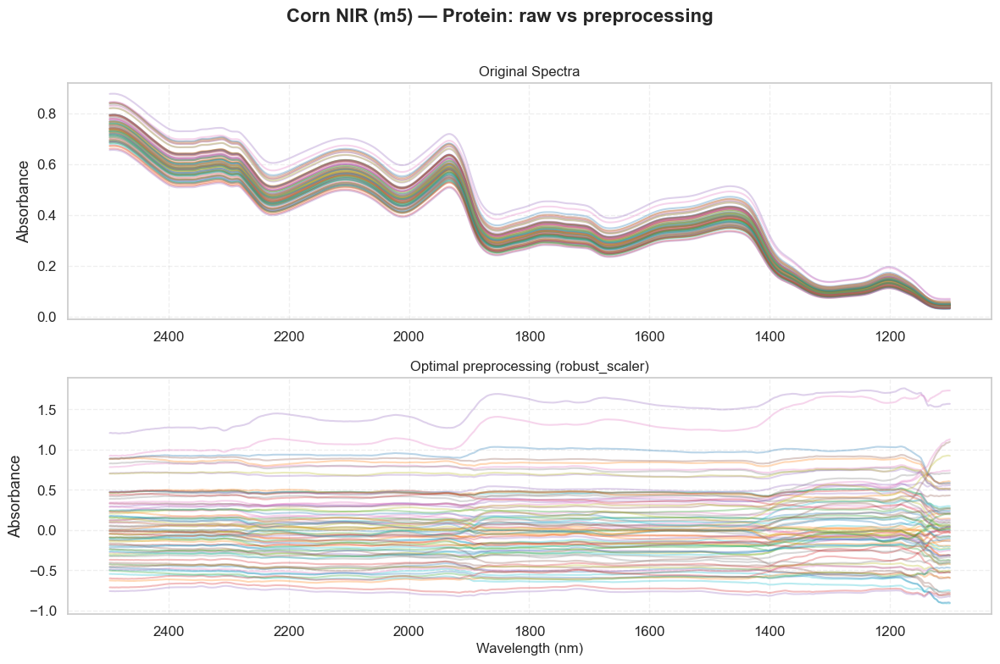

In [6]:
from sklearn.pipeline import Pipeline

prep = Pipeline(best_pipeline.steps[:-1])
X_prep = np.asarray(prep.fit_transform(X))
chain = " → ".join(s for s, _ in best_pipeline.steps[:-1])

SpectroPrepPlotter.plot_preprocessing_comparison(
    wavelengths,
    X,
    {f"Optimal preprocessing ({chain})": X_prep},
    sample_indices=None,  # all 80 spectra
    title=f"Corn NIR (m5) — {component}: raw vs preprocessing",
    xlabel="Wavelength (nm)",
    alpha=0.3,
    invert_xaxis=True,
    figsize=(12, 8),
)
plt.show()


## 6. Predicted vs reference + optimisation diagnostics

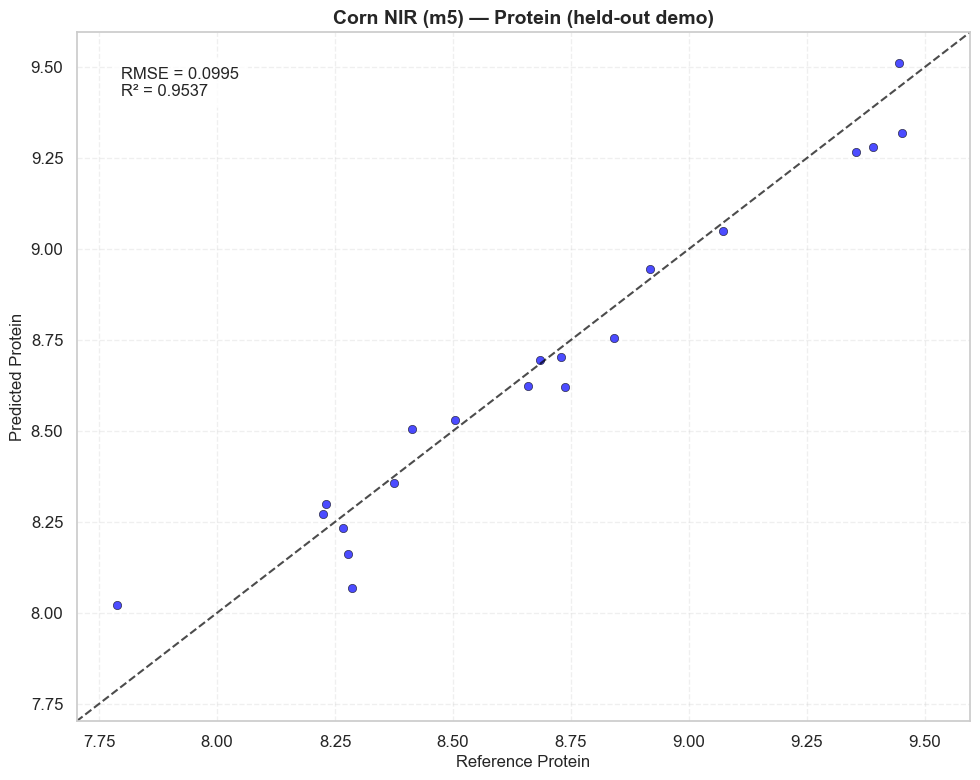

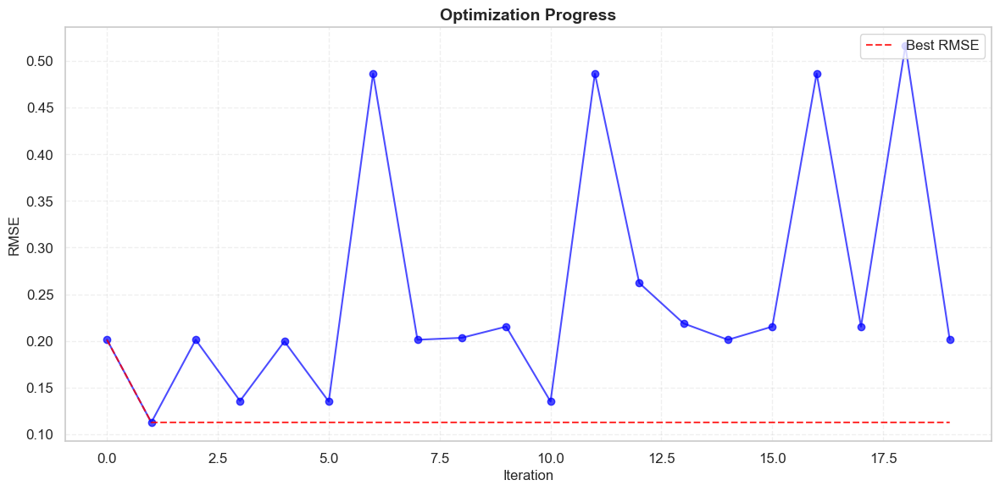

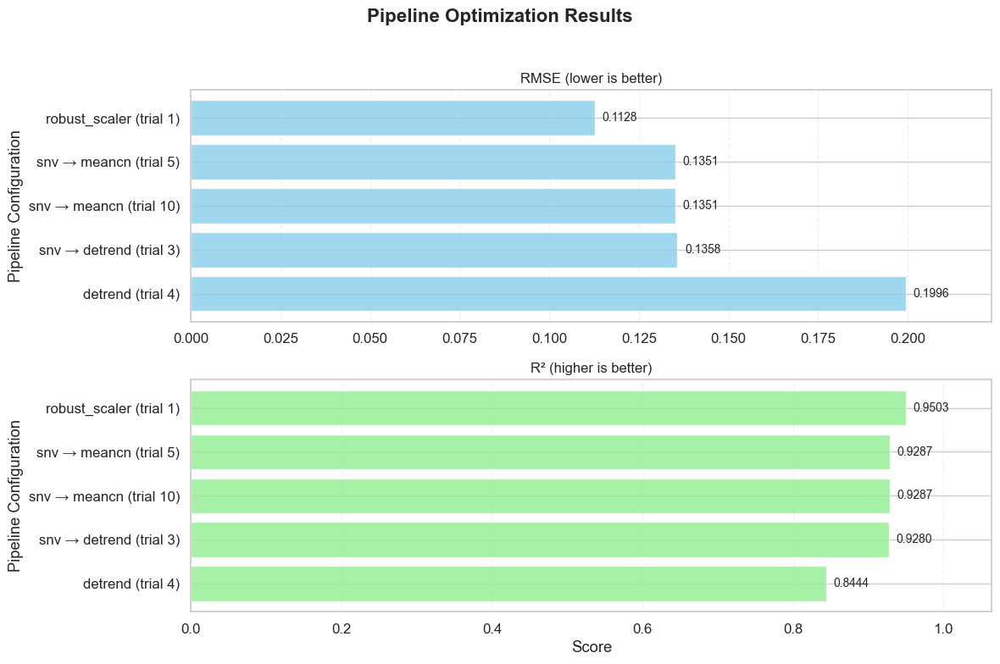

In [7]:
SpectroPrepPlotter.plot_prediction_scatter(
    y[te], preds,
    title=f"Corn NIR (m5) — {component} (held-out demo)",
    xlabel=f"Reference {component}",
    ylabel=f"Predicted {component}",
)
SpectroPrepPlotter.plot_optimization_progress(opt)
SpectroPrepPlotter.plot_optimization_results(opt, top_n=5)
plt.show()


## 7. Paper figures (nested-CV, all constituents)

If `run_corn_benchmark.py` has been executed, display the saved prediction and
preprocessing figures for every constituent (seed 0 of the ten-seed protocol).


### Raw spectra

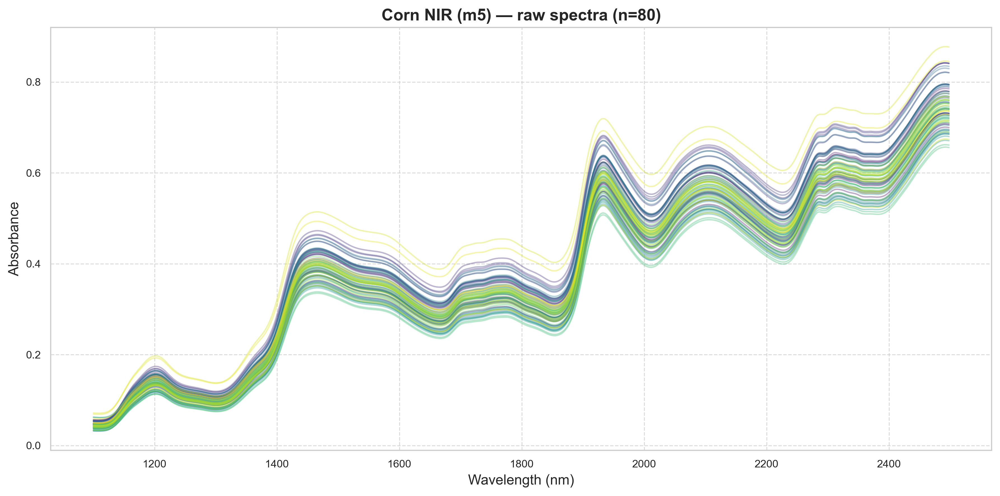

### Moisture

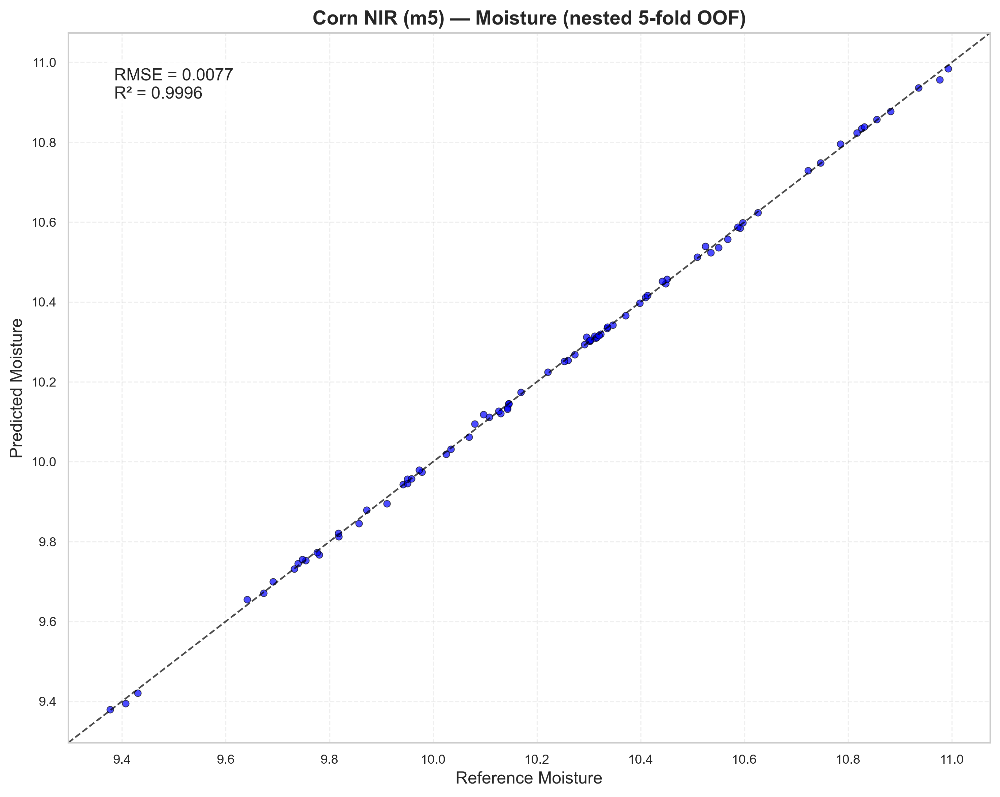

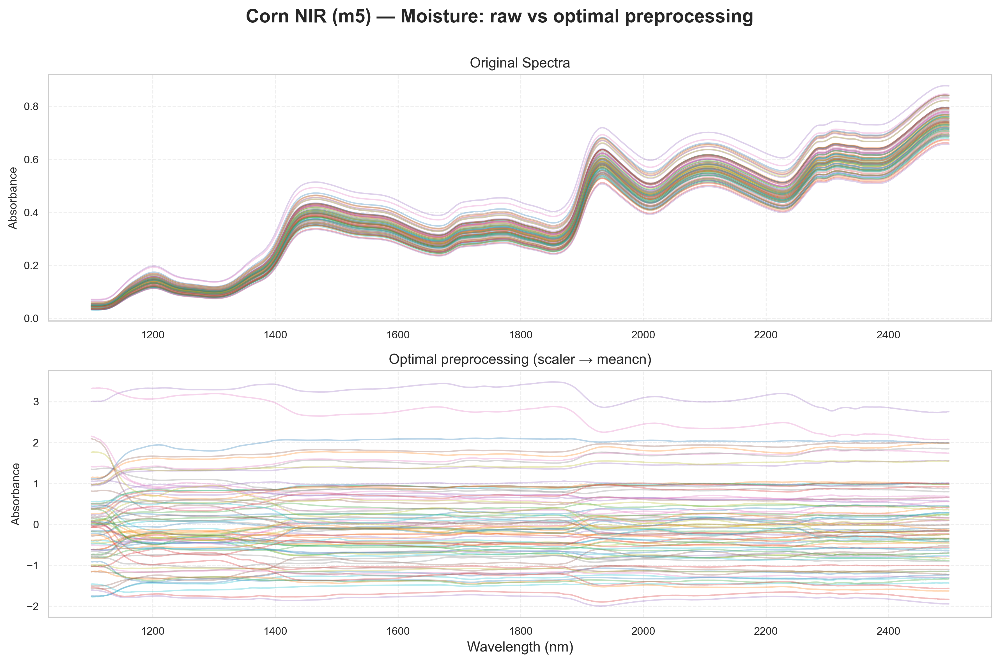

### Oil

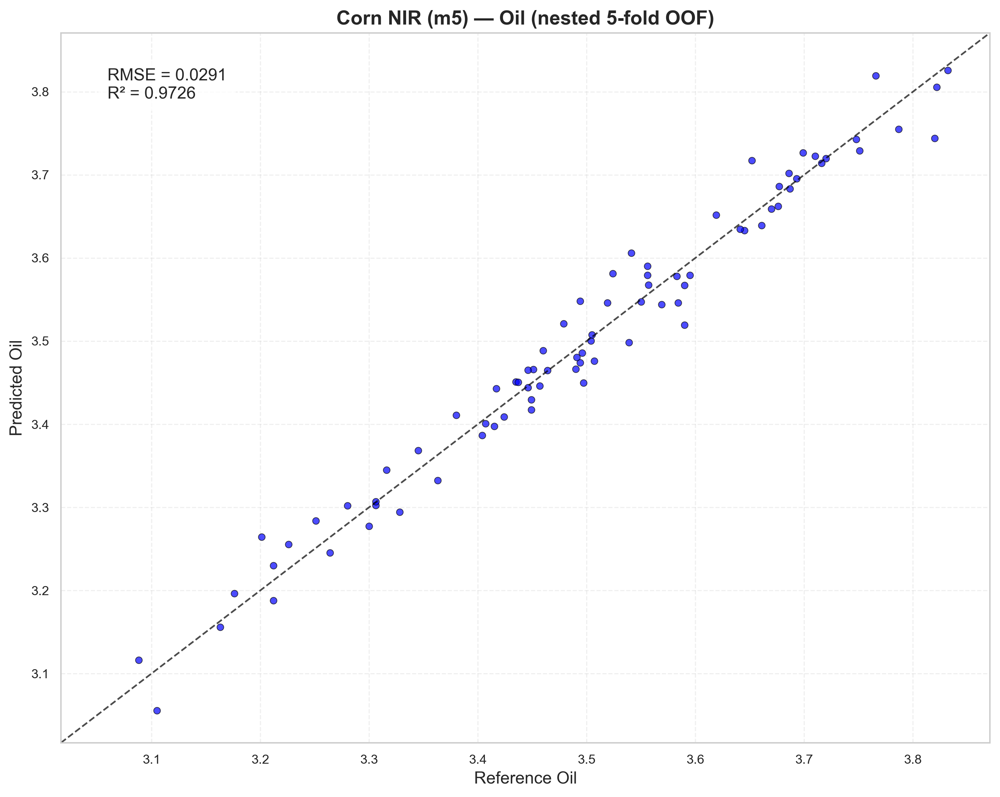

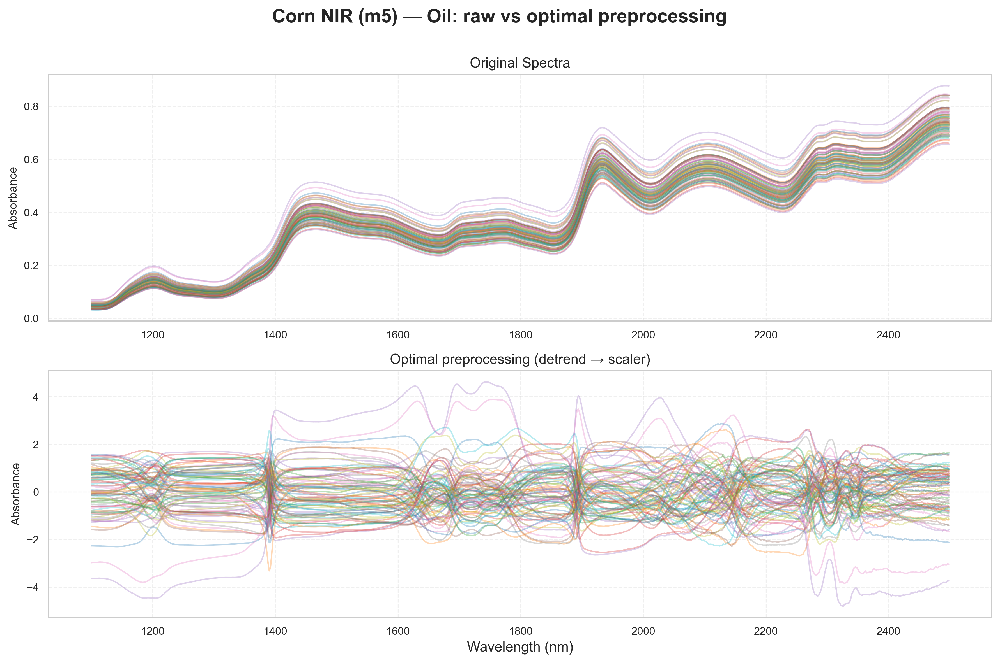

### Protein

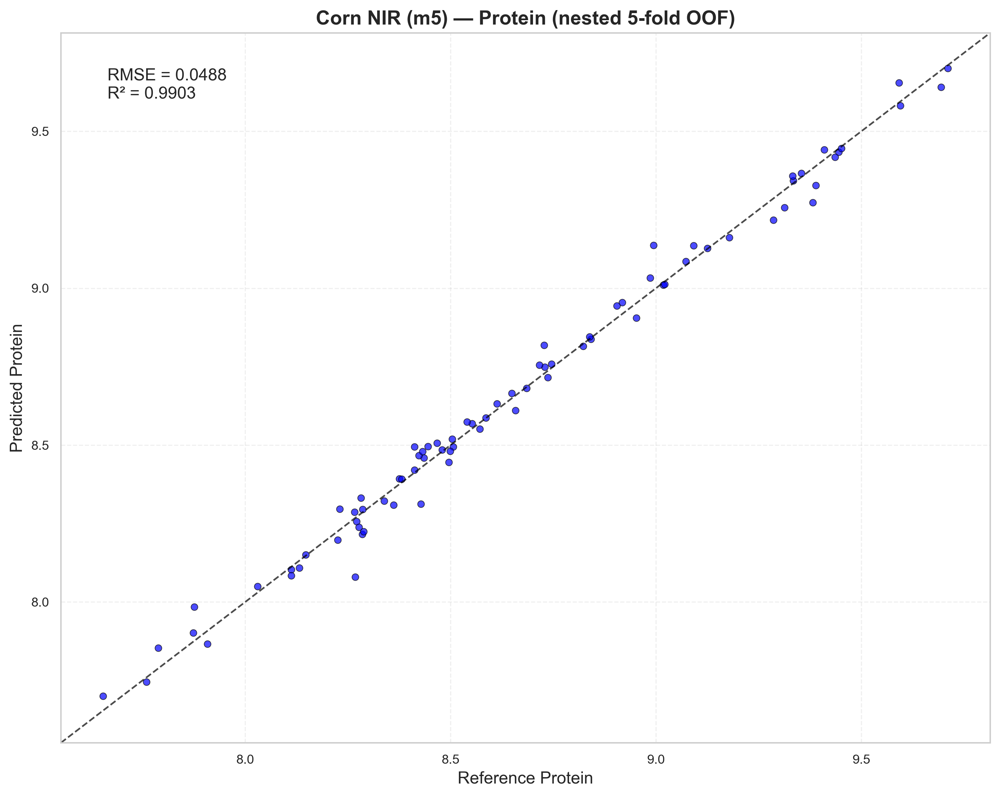

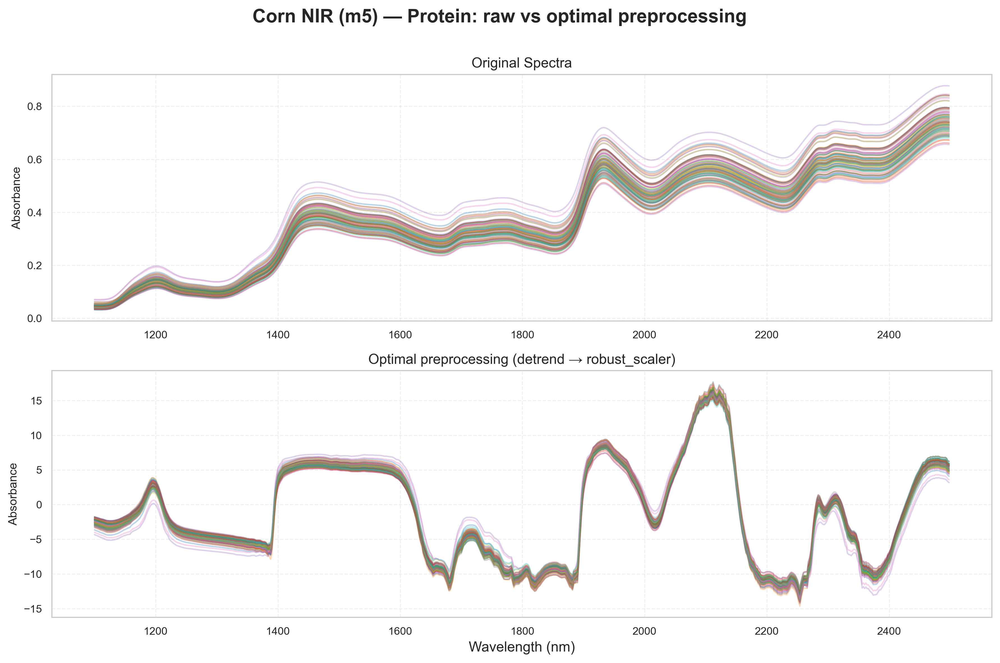

### Starch

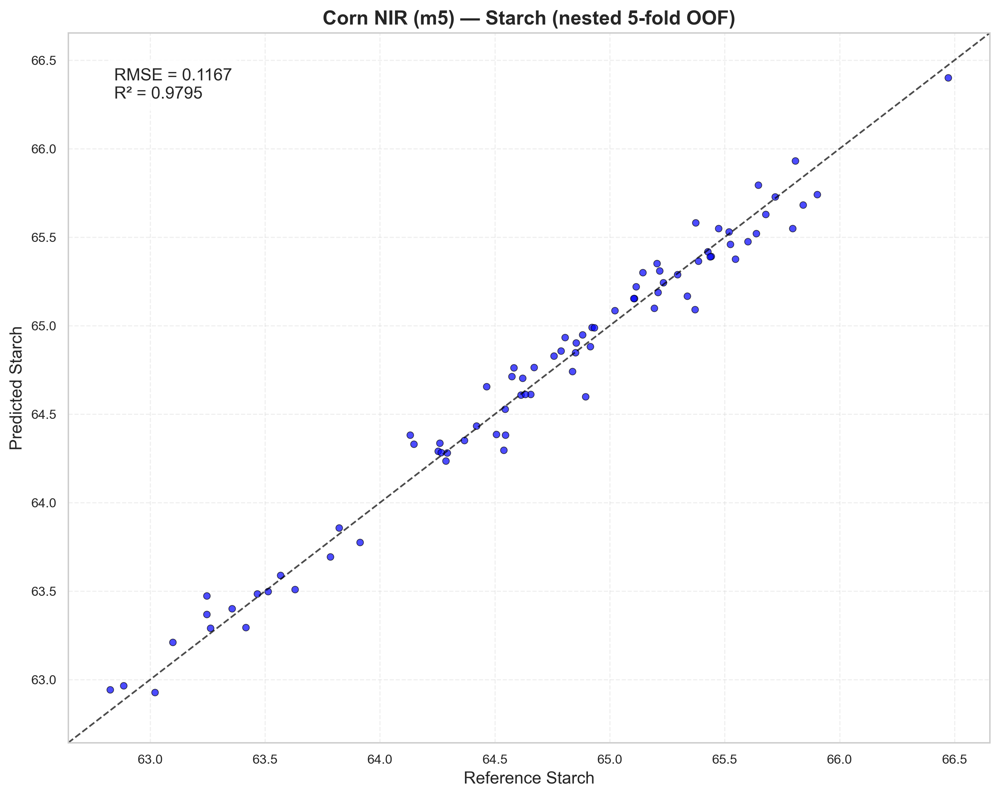

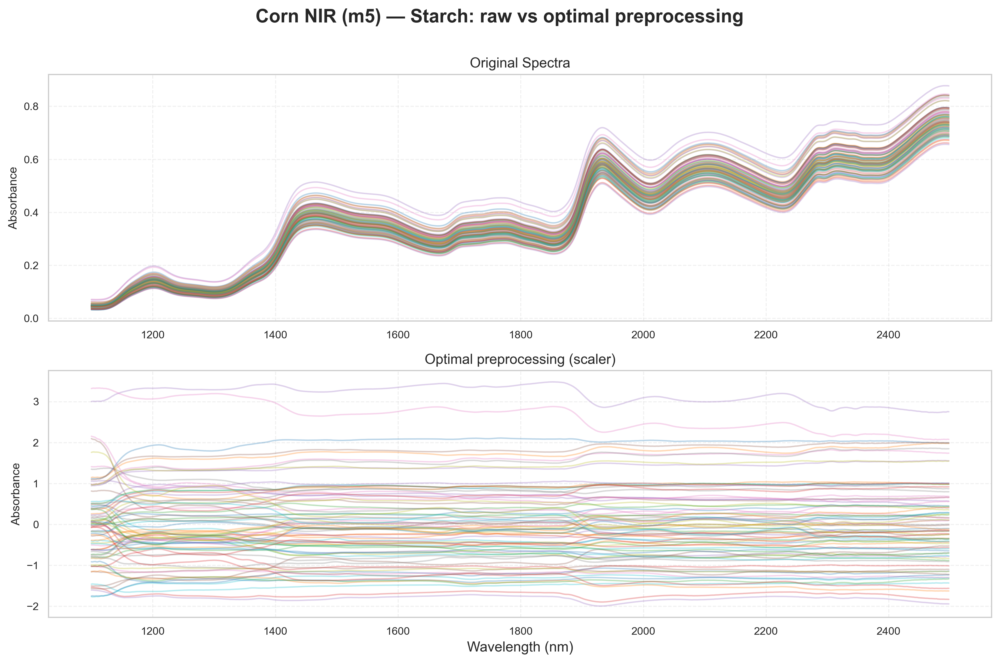

In [8]:
from IPython.display import Image, display, Markdown

fig_dir = EXAMPLES / "corn_results" / "figures"
if fig_dir.exists():
    display(Markdown("### Raw spectra"))
    display(Image(filename=str(fig_dir / "spectra_raw_full.png")))
    for name in COMPONENTS:
        display(Markdown(f"### {name}"))
        pred = fig_dir / f"prediction_{name.lower()}.png"
        prep = fig_dir / f"spectra_prep_{name.lower()}.png"
        if pred.exists():
            display(Image(filename=str(pred)))
        if prep.exists():
            display(Image(filename=str(prep)))
else:
    print("Figures not found — run examples/run_corn_benchmark.py first.")
